# SIMULASI LKS DIKMEN — KLASIFIKASI PENGADUAN PENDIDIKAN (NLP)

**Status:** latihan simulasi mandiri; **BUKAN soal atau dataset resmi LKS**.

## Acuan desain
- Kisi-kisi AI LKS Dikmen Provinsi Jawa Timur 2025: EDA 20%, preprocessing 20%, machine learning 40%, evaluasi 20%. Dokumen asli menggunakan data numerik dan KNN; ini adaptasi khusus teks, bukan reproduksi soal.
  https://id.scribd.com/document/866366688/4-Artificial-Intelligence-Kisi2-Deskripsi-Teknis-LKS-Dikmen-Tk-Jatim-2025
- Panduan Jatim 2021 menyebut data preparation, preprocessing, training classification, testing classification, dan presentation sebagai modul.
  https://id.scribd.com/document/561806665/Panduan-Teknis-Dan-Kisi-Kisi-LKS-JATIM-2021

## Kasus bisnis
Tim layanan pendidikan menerima pesan pengaduan tidak berstruktur. Bangun model **multiclass single-label** yang mengklasifikasikan **keluhan utama yang harus ditindaklanjuti**. Suatu pesan boleh menyebut beberapa masalah, tetapi label menunjukkan tindakan utama yang diminta, bukan semua kata yang muncul.

## Data & struktur
Total 4.000 pesan **fiktif/sintetis**, dibuat untuk latihan. Tidak berisi pengaduan atau data pribadi nyata.
- Train: 2,800 berlabel
- Validation: 601 berlabel
- Test: 599 tanpa label (kunci tersedia terpisah dan jangan dibuka sebelum selesai)
- File CSV UTF-8 BOM agar nyaman dibuka Excel/Pandas
- Kolom: `id_laporan`, `pesan`, `tanggal`, `kanal`, `wilayah`, `peran_pelapor`, `case_group`, `kategori` (hanya train+validation)

## Label
- `AKUN_AKSES`: 640 contoh total
- `SISTEM_JARINGAN`: 570 contoh total
- `DOKUMEN_ADMIN`: 520 contoh total
- `AKADEMIK_PEMBELAJARAN`: 480 contoh total
- `BEASISWA_BANTUAN`: 450 contoh total
- `KEUANGAN_PEMBAYARAN`: 410 contoh total
- `SARANA_PRASARANA`: 380 contoh total
- `KEAMANAN_KETERTIBAN`: 320 contoh total
- `PENDAFTARAN_MUTASI`: 230 contoh total

## Design challenge: serius tetapi proporsional
- Distribusi kelas tidak seimbang (rasio terbesar/terkecil ≈ 2.8 : 1)
- Keluhan bahasa Indonesia baku, percakapan, singkatan, salah ketik, HTML sporadis, panjang bervariasi
- Sering ada isu kedua sebagai konteks; beberapa kalimat eksplisit menyatakan *bukan* isu tersebut
- Ada duplikat persis dalam train; juga sejumlah pesan kosong pada train
- Sebagian keluarga skenario di validation dan test **tidak terdapat** dalam train (sekitar sepertiga topik keluarga per kelas); sisanya topik serupa tetapi pesan dan incident group berbeda. Ini menguji sebagian generalisasi sekaligus menjaga kesulitan tetap seimbang.
- `case_group` adalah penanda kelompok laporan terkait: **jangan gunakan sebagai fitur prediktor**; digunakan untuk audit duplikasi/splitting bila melakukan CV
- `tanggal`, `kanal`, `wilayah`, `peran_pelapor` adalah metadata tidak dirancang sebagai sumber kelas yang stabil; latih model teks utama dengan `pesan`
- Semua kategori ditetapkan pada saat membuat insiden sintetik sehingga merupakan label internal skenario. Tidak sama dengan label hasil anotasi manusia di dunia nyata.

## Rules
1. Hanya **classical machine learning** (tanpa Transformer/BERT/CNN/LSTM/LLM untuk inferensi).
2. Boleh pakai scikit-learn, pandas, numpy, matplotlib, seaborn, Gradio.
3. Dilarang fit vectorizer, feature selector, ataupun tuning model menggunakan validation/test.
4. Data validation boleh dipakai untuk memilih model, tetapi jangan menganggap skor validation sebagai test final.
5. Jangan melihat file kunci test sebelum model final dan file prediksi dibuat.
6. **Wajib** menyimpan label prediksi di `submission.csv` yang kolomnya tepat `id_laporan,kategori`.
7. Jangan memasukkan `case_group` atau `id_laporan` sebagai fitur — keduanya identifier. Jelaskan bila menggunakan fitur metadata lainnya.

## Tugas berurutan
### A. EDA (20 poin)
- Audit tipe data, missing/blank, panjang pesan, duplikasi keseluruhan dan per `pesan`, jumlah kelas, distribusi kanal/wilayah
- Analisis panjang teks per kelas, istilah yang sama antara kelas berbeda, contoh sulit/ambigu
- Jelaskan potensi shortcut learning dan kebocoran antar split
### B. Preprocessing (20 poin)
- Buat baseline minimal (lowercase + TF-IDF) sebelum preprocessing agresif
- Uji minimal dua pilihan tokenisasi/normalisasi; ablation stopword, unigram/bigram, word vs char n-gram
- Terapkan `Pipeline` agar transformasi belajar hanya dari train; tangani NaN, HTML ringan, slang secara sadar
- Audit identifikasi duplikat dan hubungannya dengan `case_group`
### C. Modeling (40 poin)
- DummyClassifier sebagai baseline
- Bandingkan sedikitnya MultinomialNB, LogisticRegression, dan LinearSVC
- Gunakan stratified atau group-aware CV sesuai hipotesis; tunjukkan tradeoff dan waktu pelatihan
- Hyperparameter tuning yang terarah; jangan buru-buru memilih model dari accuracy saja
### D. Evaluation (20 poin)
- Laporkan accuracy, macro-F1, weighted-F1, recall tiap kelas, confusion matrix
- Analisis 20 false predictions, termasuk apakah isu sekunder lebih kuat daripada isu utama
- Putuskan model akhir menggunakan validation; lalu buat test submission satu kali
- Bonus opsional: deploy dengan Gradio, tunjukkan hasil untuk input yang belum pernah dilatih

## Kriteria kelulusan (target latihan, BUKAN ambang resmi LKS)
- Nilai utama: kualitas metodologi dan validitas evaluasi, **bukan** sekadar angka skor
- Macro-F1 pada test dianjurkan sebagai metrik utama untuk memperhatikan kelas minoritas
- Jika validation jauh lebih tinggi dari test, jelaskan generalization gap dan scenario shift
- Jangan menyatakan dataset ini adalah data riil atau soal resmi

## Ukur hasil test (setelah selesai)
Simpan prediksi test ke `submission.csv`, lalu gunakan `evaluasi_submission.py` bersama file kunci test yang disimpan **terpisah dari arsip utama**. Template yang harus diisi ada pada `submission_template.csv`.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
import re

In [2]:
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [50]:
train_data=pd.read_csv("LKS_Provinsi_Dataset_Teks_Pengaduan/train.csv")
val_data=pd.read_csv("LKS_Provinsi_Dataset_Teks_Pengaduan/validation.csv")
test_data= pd.read_csv("LKS_Provinsi_Dataset_Teks_Pengaduan/test_tanpa_label.csv")

In [5]:
display(train_data.head())
print()
display(val_data.head())

,id_laporan,pesan,tanggal,kanal,wilayah,peran_pelapor,case_group,kategori
0,TR-00001,Saya wali murid dan mau menyampaikan bahwa pro...,2025-03-03,Aplikasi Mobile,Malang,Alumni,K2151D54DFB5A,AKUN_AKSES
1,TR-00002,Transkrip sekolah belum mendapat tanda tangan...,2026-10-08,Telepon,Tuban,Staf TU,K3DA4B1A1A28B,DOKUMEN_ADMIN
2,TR-00003,sy ingin membuat pengaduan: Kami menemukan mas...,2025-07-07,Telepon,Bojonegoro,Orang Tua,K6505C9F9E3D4,KEUANGAN_PEMBAYARAN
3,TR-00004,jadwal pencairan insentif pendidikan tidak diu...,2025-09-12,Formulir Web,Malang,Guru,KABE53BD04ECA,BEASISWA_BANTUAN
4,TR-00005,Iuran sekolah tercatat belum lunas meski sudah...,2026-09-03,Email,Tulungagung,Orang Tua,K9927CAFE0D2A,KEUANGAN_PEMBAYARAN


,id_laporan,pesan,tanggal,kanal,wilayah,peran_pelapor,case_group,kategori
0,VA-00001,"Sebagai siswa saya mengalami masalah, Awalnya ...",2026-08-19,WhatsApp,Blitar,Alumni,K44650EC86B0B,SISTEM_JARINGAN
1,VA-00002,Saat kegiatan belajar berjalan beberapa hari i...,2025-12-30,Email,Jombang,Guru,KF9655E79D5BF,SISTEM_JARINGAN
2,VA-00003,Bukan soal salinan kartu keluarga dinyatakan t...,2025-09-28,Telepon,Ponorogo,Warga,K44650EC86B0B,SISTEM_JARINGAN
3,VA-00004,"Assalamualaikum, izin bertanya sekaligus melap...",2026-07-12,Aplikasi Mobile,Nganjuk,Siswa,K1E49F0716ADB,SISTEM_JARINGAN
4,VA-00005,Halaman pembayaran digital terus memuat tanpa ...,2026-08-20,WhatsApp,Batu,Orang Tua,K458EEADA7B13,SISTEM_JARINGAN


In [7]:
display(train_data.info())
print("-"*40)
display(val_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 2800 entries, 0 to 2799
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_laporan     2800 non-null   str  
 1   pesan          2777 non-null   str  
 2   tanggal        2800 non-null   str  
 3   kanal          2800 non-null   str  
 4   wilayah        2800 non-null   str  
 5   peran_pelapor  2800 non-null   str  
 6   case_group     2800 non-null   str  
 7   kategori       2800 non-null   str  
dtypes: str(8)
memory usage: 175.1 KB


None

----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 601 entries, 0 to 600
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   id_laporan     601 non-null    str  
 1   pesan          601 non-null    str  
 2   tanggal        601 non-null    str  
 3   kanal          601 non-null    str  
 4   wilayah        601 non-null    str  
 5   peran_pelapor  601 non-null    str  
 6   case_group     601 non-null    str  
 7   kategori       601 non-null    str  
dtypes: str(8)
memory usage: 37.7 KB


None

In [51]:
display(train_data.shape)
print()
display(val_data.shape)
print()
display(test_data.shape)

(2800, 8)

(601, 8)

(599, 7)

In [9]:
display(train_data.describe())
print()
display(val_data.describe())

,id_laporan,pesan,tanggal,kanal,wilayah,peran_pelapor,case_group,kategori
count,2800,2777,2800,2800,2800,2800,2800,2800
unique,2800,2692,694,6,22,6,705,9
top,TR-00001,,2025-03-03,Formulir Web,Pacitan,Guru,K2172AB9E60BC,AKUN_AKSES
freq,1,19,10,498,156,499,11,448


,id_laporan,pesan,tanggal,kanal,wilayah,peran_pelapor,case_group,kategori
count,601,601,601,601,601,601,601,601
unique,601,601,404,6,22,6,158,9
top,VA-00001,"Sebagai siswa saya mengalami masalah, Awalnya ...",2026-02-06,Aplikasi Mobile,Bojonegoro,Alumni,K69C0D6FB14ED,AKUN_AKSES
freq,1,1,4,115,35,112,9,96


In [10]:
display(train_data.isna().sum())
print("(GABUT)"*3)
display(val_data.isna().sum())

id_laporan        0
pesan            23
tanggal           0
kanal             0
wilayah           0
peran_pelapor     0
case_group        0
kategori          0
dtype: int64

(GABUT)(GABUT)(GABUT)


id_laporan       0
pesan            0
tanggal          0
kanal            0
wilayah          0
peran_pelapor    0
case_group       0
kategori         0
dtype: int64

In [11]:
display(train_data.duplicated().sum())
print()
display(val_data.duplicated().sum())

np.int64(0)

np.int64(0)

In [12]:
summary_train = pd.DataFrame({
    'dtype': train_data.dtypes,
    'missing': train_data.isna().sum(),
    'missing_pct': (100*train_data.isna().mean()).round(3),
    'n_unique_nonnull': train_data.nunique(dropna=True)
})
display(summary_train)
print("="*55)
summary_val= pd.DataFrame({
    'dtype': val_data.dtypes,
    'missing': val_data.isna().sum(),
    'missing_pct': (100*val_data.isna().mean()).round(3),
    'n_unique_nonnull': val_data.nunique(dropna=True)
})
display(summary_val)

,dtype,missing,missing_pct,n_unique_nonnull
id_laporan,str,0,0.000,2800
pesan,str,23,0.821,2692
tanggal,str,0,0.000,694
kanal,str,0,0.000,6
wilayah,str,0,0.000,22
peran_pelapor,str,0,0.000,6
case_group,str,0,0.000,705
kategori,str,0,0.000,9


,dtype,missing,missing_pct,n_unique_nonnull
id_laporan,str,0,0.0,601
pesan,str,0,0.0,601
tanggal,str,0,0.0,404
kanal,str,0,0.0,6
wilayah,str,0,0.0,22
peran_pelapor,str,0,0.0,6
case_group,str,0,0.0,158
kategori,str,0,0.0,9


In [13]:
train_data.columns

Index(['id_laporan', 'pesan', 'tanggal', 'kanal', 'wilayah', 'peran_pelapor',
       'case_group', 'kategori'],
      dtype='str')

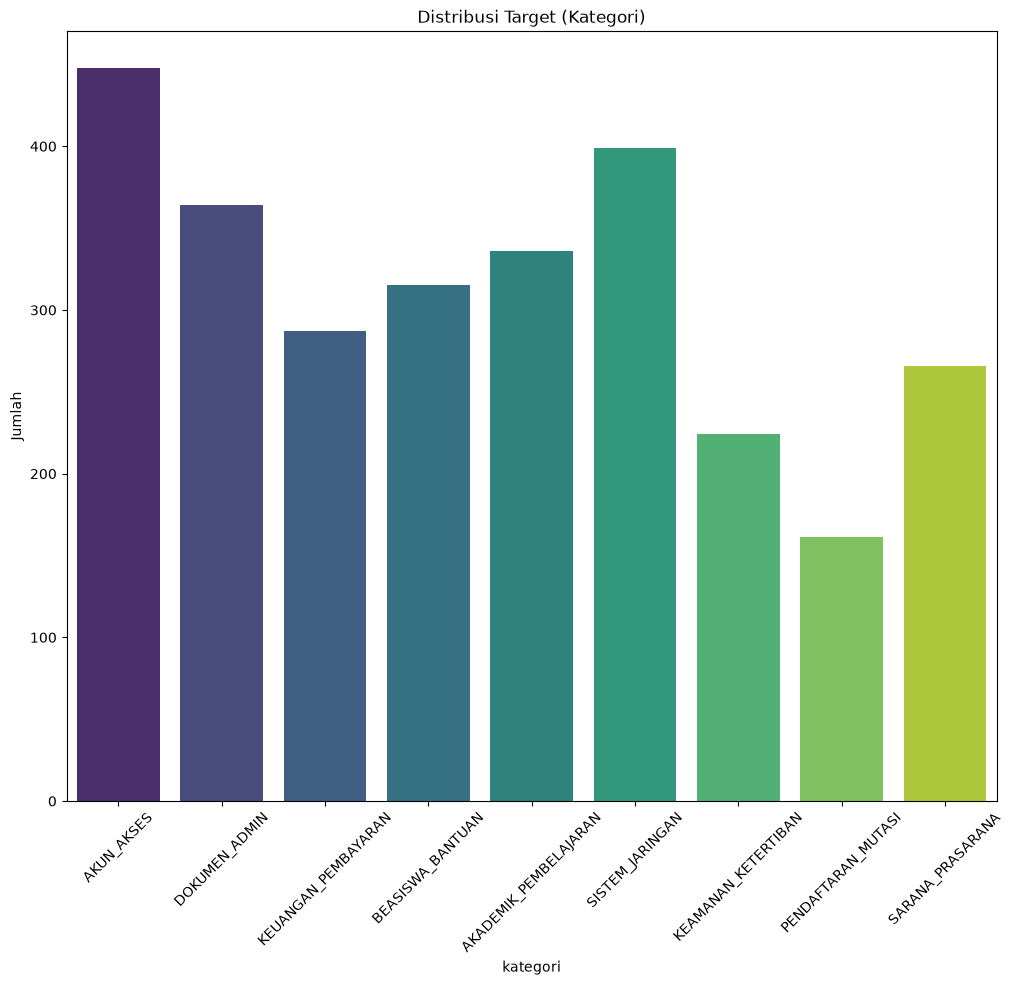

In [14]:
plt.figure(figsize=(12,10))
sns.countplot(data=train_data, x='kategori', hue='kategori', palette='viridis')
plt.xticks(rotation=45)
plt.title("Distribusi Target (Kategori)")
plt.ylabel("Jumlah")
plt.show()

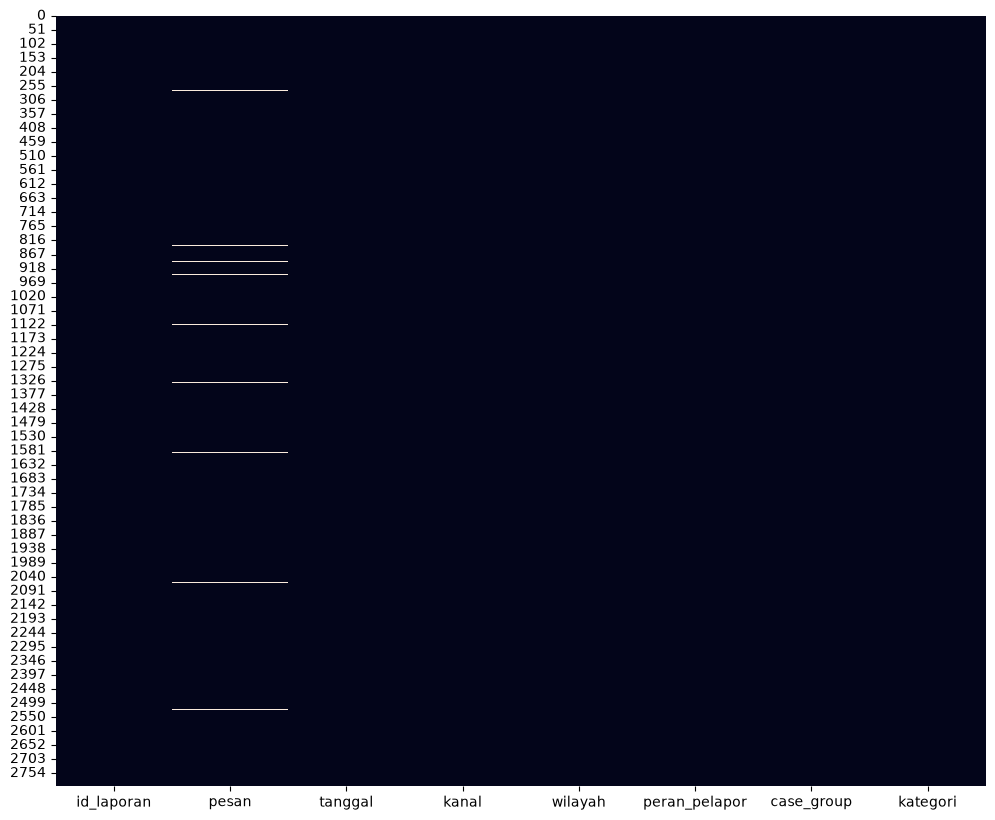

In [15]:
plt.figure(figsize=(12,10))
sns.heatmap(train_data.isna(), cbar=False)
plt.show()

In [16]:
for col in train_data.columns:
    counts = train_data[col].value_counts(dropna=False)
    pct = train_data[col].value_counts(dropna=False, normalize=True) * 100
    summary = pd.DataFrame({'Count': counts, 'Percentage (%)': pct.round(2)})
    display(summary)
    print('\n' + '-' * 40 + '\n')

,Count,Percentage (%)
id_laporan,,
TR-00001,1,0.04
TR-00002,1,0.04
TR-00003,1,0.04
TR-00004,1,0.04
TR-00005,1,0.04
TR-00006,1,0.04
TR-00007,1,0.04
TR-00008,1,0.04
TR-00009,1,0.04



----------------------------------------



,Count,Percentage (%)
pesan,,
NaN,23,0.82
,19,0.68
Kami menemukan masalah pada sesi layanan pagi: uang daftar ulang yang dibatalkan belum dikembalikan . Wali murid menunggu pengembalian setoran . Kami sudah mencoba menanyakan ini . Bisa dibantu untuk selesaikan restitusi biaya . Ini sudah mengganggu aktivitas .,3,0.11
Ada masalah dari sekolah kami: Kami menemukan masalah di SMK wilayah kecamatan kami: meja laboratorium goyah saat digunakan. Alat praktikum berisiko jatuh. Kami sudah mencoba menanyakan ini. Harap perkuat perabot laboratorium.,3,0.11
"Saya wali murid dan mau menyampaikan bahwa profil pengguna tetap aktif di gawai yang hilang beberapa hari ini. Sampai sekarang, data siswa berpotensi terbaca orang lain. Mohon petugas segera keluarkan semua sesi dari perangkat lama ya. Takut terjadi kesalahan lebih besar.",2,0.07
Saya ingin membuat pengaduan: Kami menemukan masalah di lingkungan sekolah kami: alamat surel pemulihan akun sudah tidak aktif. Pemulihan kata sandi selalu gagal. Kami sudah mencoba menanyakan ini. Mohon petugas segera perbarui kontak pemulihan. Untuk bantuan ongkos transport siswa belum dibayarkan kami sudah membuat laporan terpisah. Jangan sampai terulang.,2,0.07
"Lapor ya, Kami menemukan masalah untuk siswa kelas XI: halaman dashboard hanya menampilkan layar putih. Menu penting tidak muncul di peramban. Kami sudah mencoba menanyakan ini. Mohon petugas segera pulihkan tampilan situs. Ini sudah mengganggu aktivitas.",2,0.07
"Atap ruang praktik bocor saat hujan. Peralatan belajar terkena tetesan air. Mohon petugas segera perbaiki bagian atap yang rusak di unit layanan pendidikan kecamatan, mohon infonya. Ini masih berlanjut.",2,0.07
"Permisi kak, mau lapor. Kami menemukan masalah untuk siswa kelas XI: profil pengguna tetap aktif di gawai yang hilang. Data siswa berpotensi terbaca orang lain. Kami sudah mencoba menanyakan ini. Bisa dibantu untuk keluarkan semua sesi dari perangkat lama. Jangan sampai terulang.",2,0.07



----------------------------------------



,Count,Percentage (%)
tanggal,,
2025-03-03,10,0.36
2026-01-30,10,0.36
2026-01-22,10,0.36
2025-03-07,10,0.36
2026-02-18,10,0.36
2025-02-20,9,0.32
2026-03-01,9,0.32
2025-05-07,9,0.32
2025-09-23,9,0.32



----------------------------------------



... (6 outputs left out)

,Count,Percentage (%)
case_group,,
K2172AB9E60BC,11,0.39
K7B1E7CA61D5C,11,0.39
KD480AF812278,9,0.32
K6BA8A07C0258,9,0.32
KDB014EA94808,9,0.32
K82C58AE2FFB5,9,0.32
K31A09A5913FF,9,0.32
KBC1D3E797DAD,9,0.32
K9183DA387F98,9,0.32



----------------------------------------



,Count,Percentage (%)
kategori,,
AKUN_AKSES,448,16.00
SISTEM_JARINGAN,399,14.25
DOKUMEN_ADMIN,364,13.00
AKADEMIK_PEMBELAJARAN,336,12.00
BEASISWA_BANTUAN,315,11.25
KEUANGAN_PEMBAYARAN,287,10.25
SARANA_PRASARANA,266,9.50
KEAMANAN_KETERTIBAN,224,8.00
PENDAFTARAN_MUTASI,161,5.75



----------------------------------------



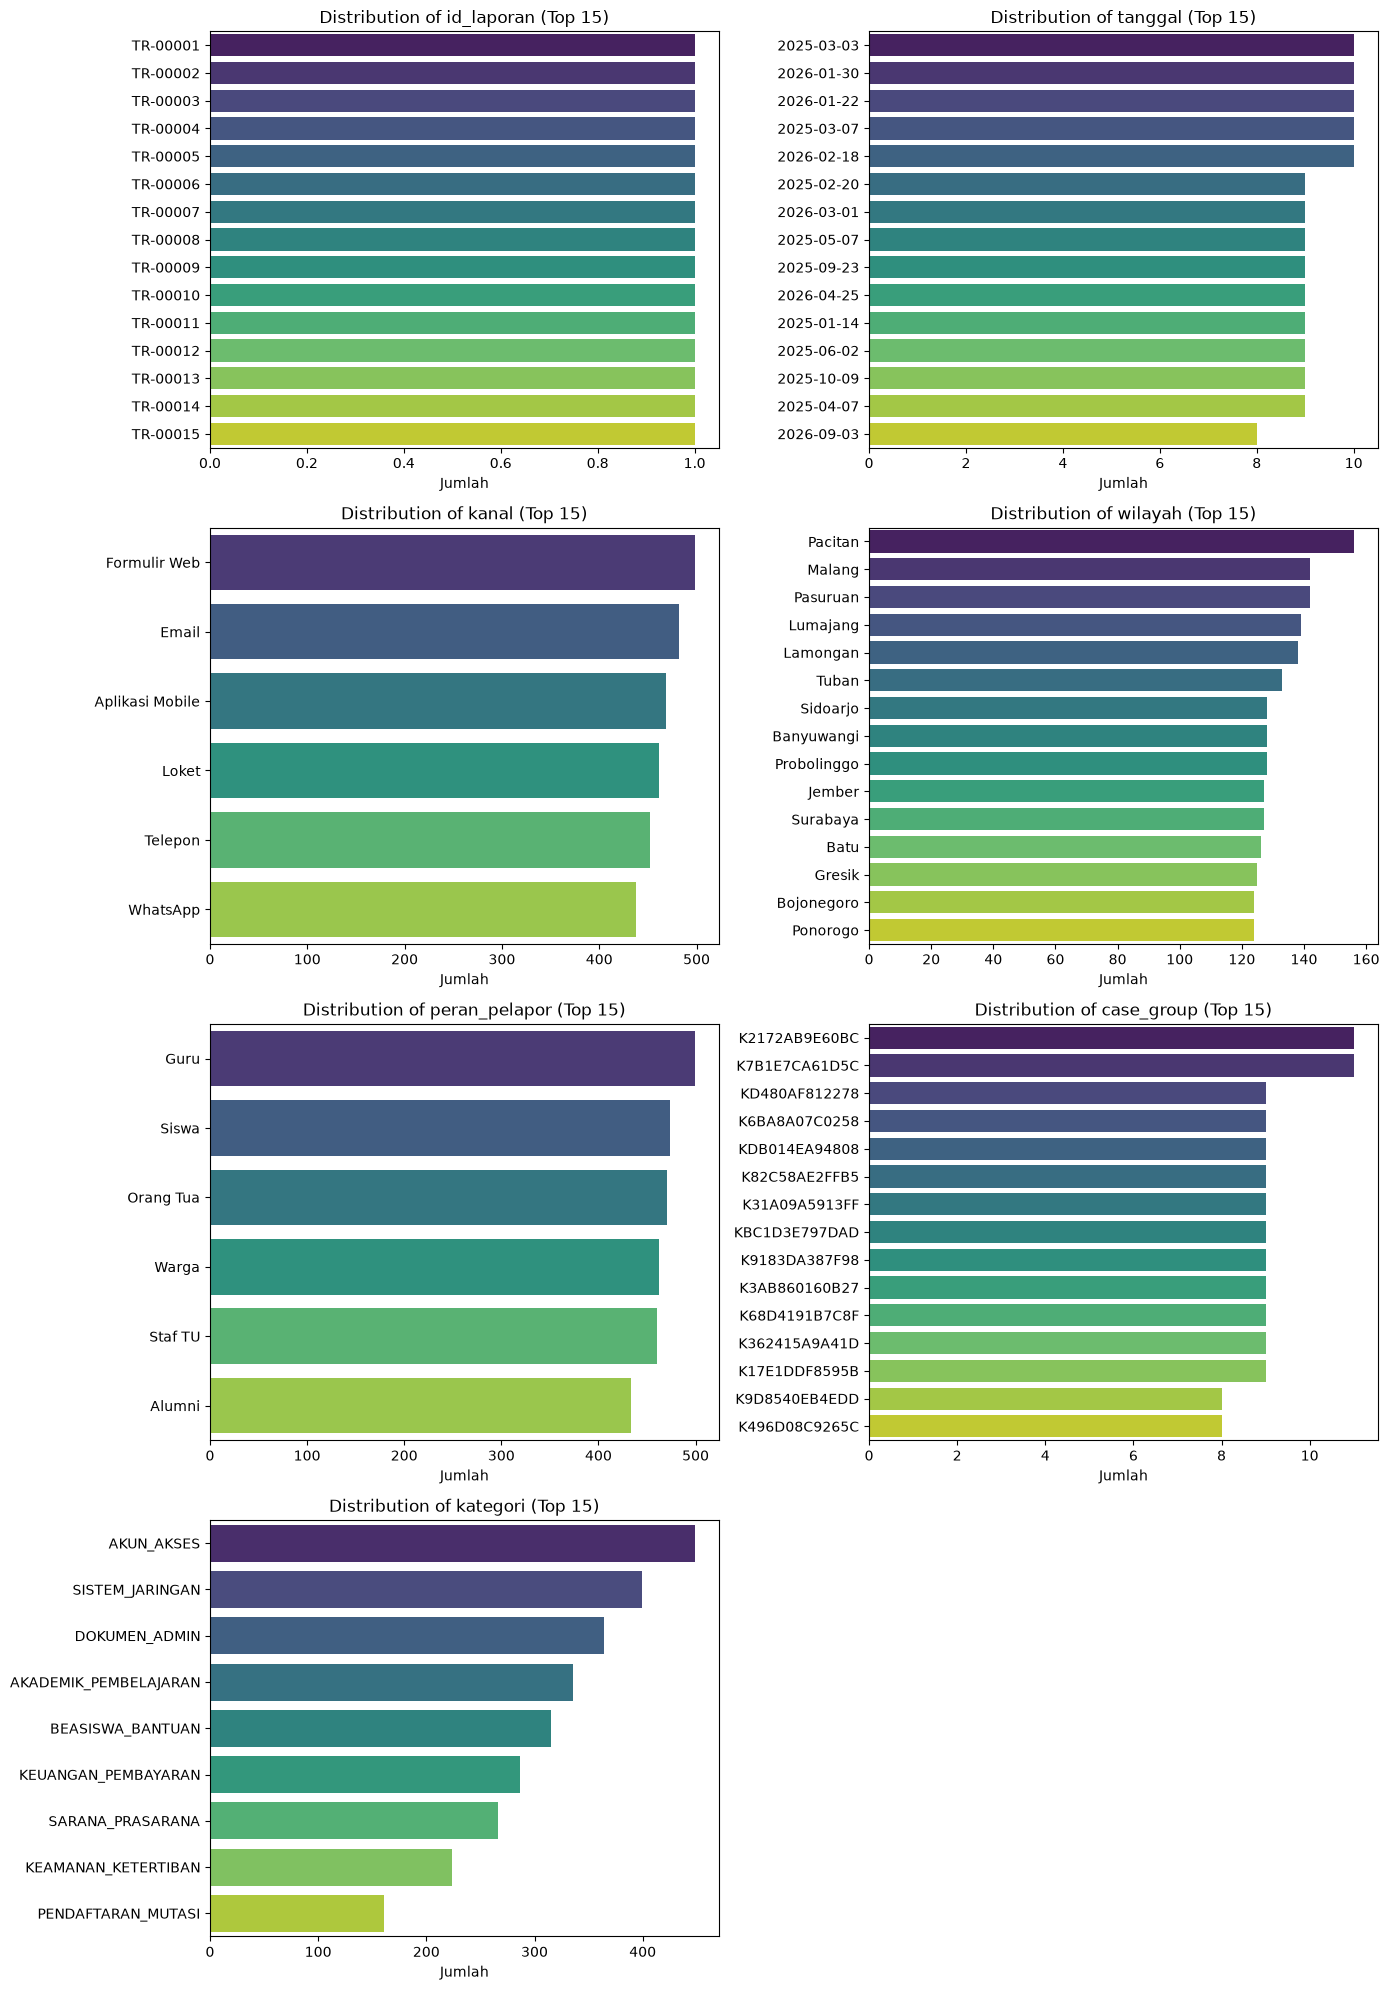

In [17]:
n_cols = 2
n_rows = (len(train_data.columns) + 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 5 * n_rows))
axes = axes.flatten()
for i, col in enumerate(train_data.drop(columns=['pesan']).columns):
    top_cat = train_data[col].value_counts().nlargest(15).index
    sns.countplot(data=train_data[train_data[col].isin(top_cat)], legend=False, y=col, hue=col, hue_order=top_cat, 
                  order=top_cat, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Distribution of {col} (Top 15)')
    axes[i].set_xlabel('Jumlah')
    axes[i].set_ylabel('')

for j in range(i + 1, len(axes)):
  fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [53]:
blank_train = train_data['pesan'].fillna('').str.strip().eq('').sum()
print(f"Pesan kosong di Train: {blank_train}")

Pesan kosong di Train: 19


In [42]:
dup_all = train_data.duplicated().sum()
dup_pesan = train_data.duplicated(subset=['pesan']).sum()
overlap_val = set(train_data['pesan'].dropna()).intersection(set(val_data['pesan'].dropna()))

In [64]:
print(f"Duplikat seluruh kolom (Train): {dup_all}")
print(f"Duplikat teks pesan (Train): {dup_pesan}")
print(f"Pesan Train yang bocor ke Validation: {len(overlap_val)}")

Duplikat seluruh kolom (Train): 0
Duplikat teks pesan (Train): 85
Pesan Train yang bocor ke Validation: 0


In [57]:
dup_df = train_data[train_data.duplicated(subset='pesan', keep=False)].sort_values('pesan')
display("Contoh duplikat & case_group:", dup_df[['id_laporan', 'case_group', 'kategori', 'pesan']].head(6))

'Contoh duplikat & case_group:'

,id_laporan,case_group,kategori,pesan
1113,TR-01114,K9183DA387F98,KEUANGAN_PEMBAYARAN,
2163,TR-02164,K03152E9372BF,AKADEMIK_PEMBELAJARAN,
2242,TR-02243,KC458C1338848,SARANA_PRASARANA,
1906,TR-01907,K2FD6F1F37E7C,DOKUMEN_ADMIN,
1514,TR-01515,K60A06A7DE343,AKUN_AKSES,
1492,TR-01493,K93AEF53407B9,AKADEMIK_PEMBELAJARAN,


In [62]:
train_data['jumlah_kata'] = train_data['pesan'].str.split().str.len()
display(train_data.groupby('kategori')['jumlah_kata'].describe()[['count', 'mean', '50%', 'max']])

,count,mean,50%,max
kategori,,,,
AKADEMIK_PEMBELAJARAN,332.0,30.804217,30.0,54.0
AKUN_AKSES,445.0,32.579775,32.0,63.0
BEASISWA_BANTUAN,314.0,31.117834,30.0,58.0
DOKUMEN_ADMIN,361.0,31.232687,31.0,51.0
KEAMANAN_KETERTIBAN,221.0,31.162896,30.0,56.0
KEUANGAN_PEMBAYARAN,285.0,30.182456,30.0,54.0
PENDAFTARAN_MUTASI,159.0,32.037736,32.0,53.0
SARANA_PRASARANA,263.0,29.817490,30.0,53.0
SISTEM_JARINGAN,397.0,31.624685,31.0,59.0


In [21]:
import re
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

In [67]:
stop_words = StopWordRemoverFactory()
stop_words_dict = stop_words.get_stop_words()

In [70]:
from sklearn.feature_extraction.text import CountVectorizer
top_words={}
for w in train_data['kategori'].unique():
    vec = CountVectorizer(max_features=25, stop_words=stop_words_dict, token_pattern=r'\b\w+(?:-\w+)*\b')
    vec.fit(train_data[train_data['kategori'] == w]['pesan'].fillna(''))
    top_words[w] = set(vec.get_feature_names_out())

common_words=set.intersection(*top_words.values())
display("Kata umum di top 25 semua kelas: ", common_words)

'Kata umum di top 25 semua kelas: '

{'harap', 'sekolah'}

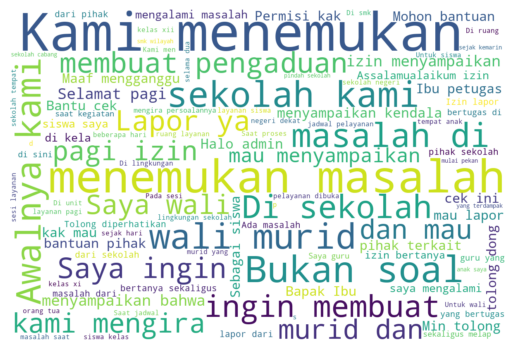

In [78]:
from wordcloud import WordCloud
wc = WordCloud(
    width=1200,
    height=800,
    background_color="white",
    max_words=100,
    colormap="viridis",
).generate(train_data['pesan'].to_string())
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.show()

In [73]:
display(train_data[train_data['pesan'].str.contains('bukan|padahal|tapi', case=False, na=False)][['kategori', 'pesan']].head(5))

,kategori,pesan
14,SISTEM_JARINGAN,Saya wali murid dan mau menyampaikan bahwa Buk...
19,AKADEMIK_PEMBELAJARAN,"Lapor ya, Bukan soal portal sekolah memunculka..."
27,BEASISWA_BANTUAN,"Selamat pagi, izin menyampaikan kendala. Awaln..."
39,KEUANGAN_PEMBAYARAN,"Permisi kak, mau lapor. Bukan soal alamat domi..."
43,KEUANGAN_PEMBAYARAN,"Halo admin, Bukan soal surel sekolah sering te..."


In [74]:
words_negasi = {'tidak', 'bukan', 'jangan', 'belum', 'kurang', 'tanpa', 'padahal', 'tapi', 'tetapi'}
stopwords_id = set(stop_words_dict)
stopwords_id = stopwords_id - words_negasi

In [75]:
stem_factory = StemmerFactory()
stemmer = stem_factory.create_stemmer()

In [76]:
memo_stem = {}
def stem_kata(kata):
    if kata not in memo_stem:
        memo_stem[kata] = stemmer.stem(kata)
    return memo_stem[kata]

In [88]:
import html

def clean_texts(texts):
    if pd.isna(texts):
        return ""

    texts = html.unescape(str(texts))
    texts = re.sub(r'<[^>]+>', ' ', texts)
    texts = texts.lower()
    texts = re.sub(r'[^a-z0-9\s]', ' ', texts)
    res=[]
    for w in texts.split():
        if len(w) > 1 and w not in stopwords_id:
            base_w = stem_kata(w)
            if base_w not in stopwords_id:
                res.append(base_w)
                
    return " ".join(res) 

In [80]:
def preprocess(text_data):
    return [clean_texts(t) for t in text_data]


In [82]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

preprocessor = FunctionTransformer(preprocess)
pipe = Pipeline([
    ('prep', preprocessor),
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

In [84]:
train_bersih = train_data.dropna(subset=['pesan']).copy()
train_bersih = train_bersih[train_bersih['pesan'].str.strip() != '']
train_bersih = train_bersih.drop_duplicates(subset=['pesan', 'kategori'])

In [93]:
from sklearn.metrics import f1_score

pipe.fit(train_bersih['pesan'], train_bersih['kategori'])
prediksi_val = pipe.predict(val_data['pesan'].fillna(''))
display("Validation F1 Macro:", f1_score(val_data['kategori'], prediksi_val, average='macro'))

'Validation F1 Macro:'

0.8206206370034647

In [95]:
X_train = train_bersih['pesan']
y_train = train_bersih['kategori']
X_val = val_data['pesan'].fillna('')
y_val = val_data['kategori']

In [96]:
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.metrics import accuracy_score

def light_clean(data):
    res = []
    for t in data:
        t = html.unescape(str(t)).lower()
        t = re.sub(r'<[^>]+>', ' ', t)
        t = re.sub(r'[^a-z0-9\s]', ' ', t)
        res.append(" ".join(t.split()))
    return res

In [110]:
scenario_ablation = {
    "Baseline Mentah (Lower + Word Unigram)": Pipeline([
        ('tfidf', TfidfVectorizer(lowercase=True, ngram_range=(1, 1))),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    "Clean Ringan (HTML/Regex) + Unigram": Pipeline([
        ('prep', FunctionTransformer(light_clean)),
        ('tfidf', TfidfVectorizer(ngram_range=(1, 1), sublinear_tf=True)),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    "Sastrawi (Stopword+Stem) + Unigram": Pipeline([
        ('prep', FunctionTransformer(preprocess)),
        ('tfidf', TfidfVectorizer(ngram_range=(1, 1), sublinear_tf=True)),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    "Clean Sastrawi + Word Bigram (1, 2)": Pipeline([
        ('prep', FunctionTransformer(preprocess)),
        ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    "Clean Ringan + Char N-Gram (3, 5)": Pipeline([
        ('prep', FunctionTransformer(light_clean)),
        ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, sublinear_tf=True)),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ]),
    "Sastrawi Word(1,2) + Ringan Char(3,5)": Pipeline([
        ('fitur', FeatureUnion([
            ('word', Pipeline([
                ('prep', FunctionTransformer(preprocess)),
                ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True))
            ])),
            ('char', Pipeline([
                ('prep', FunctionTransformer(light_clean)),
                ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, sublinear_tf=True))
            ]))
        ])),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
    ])
}

In [113]:
res_ablation = []
for name, pipe in scenario_ablation.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_val)
    
    res_ablation.append({
        'Skenario': name,
        'Val_Accuracy': round(accuracy_score(y_val, pred), 4),
        'Val_Macro_F1': round(f1_score(y_val, pred, average='macro'), 4),
    })

df_ablation = pd.DataFrame(res_ablation)
display(df_ablation)

,Skenario,Val_Accuracy,Val_Macro_F1
0,Baseline Mentah (Lower + Word Unigram),0.8752,0.8709
1,Clean Ringan (HTML/Regex) + Unigram,0.8686,0.8652
2,Sastrawi (Stopword+Stem) + Unigram,0.8719,0.8667
3,"Clean Sastrawi + Word Bigram (1, 2)",0.8253,0.8205
4,"Clean Ringan + Char N-Gram (3, 5)",0.8636,0.8641
5,"Sastrawi Word(1,2) + Ringan Char(3,5)",0.8486,0.8458
